# Forecast

SARIMA was picked in the models notebook. This checks its prediction intervals on the backtest, then refits it on every day up to 30 Oct 2026 and forecasts the next 14.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from src.data import model_series
from src.models import sarima_forecast

FIGURES = "../reports/figures/"

In [2]:
y, usable = model_series(pd.read_parquet("../data/daily.parquet"))

## Interval coverage on the backtest

In [3]:
origins = pd.date_range("2024-11-04", y.index[-14], freq="14D")
rows = []
for origin in origins:
    for level, alpha in [("80%", 0.2), ("95%", 0.05)]:
        f = sarima_forecast(y[y.index < origin], 14, alpha=alpha)
        actual = y.reindex(f.index)
        real = usable.reindex(f.index)
        rows.append(pd.DataFrame({
            "level": level,
            "inside": ((actual >= f["lower"]) & (actual <= f["upper"]))[real],
            "winter": f.index[real].month.isin([11, 12, 1, 2, 3]),
        }))
coverage = pd.concat(rows)
coverage.groupby("level")["inside"].mean().round(3)

level
80%    0.820
95%    0.929
Name: inside, dtype: float64

In [4]:
coverage[coverage["level"] == "80%"].groupby("winter")["inside"].mean().round(3)

winter
False    0.899
True     0.713
Name: inside, dtype: float64

The 80% intervals contain the actual on 82.0% of backtest days and the 95% ones on 92.9%, so overall they're about right. They're too narrow in winter, though (71.3% for the 80% interval from November to March) and a bit too wide the rest of the year (89.9%).

## The next 14 days

In [5]:
forecast = sarima_forecast(y, 14)
wide = sarima_forecast(y, 14, alpha=0.05)
forecast["lower_95"] = wide["lower"]
forecast["upper_95"] = wide["upper"]
forecast.round()

,forecast,lower,upper,lower_95,upper_95
2026-10-31,1641.0,1281.0,2103.0,1123.0,2398.0
2026-11-01,1940.0,1422.0,2645.0,1207.0,3117.0
2026-11-02,2766.0,1982.0,3860.0,1662.0,4605.0
2026-11-03,2755.0,1956.0,3881.0,1632.0,4653.0
2026-11-04,2827.0,1999.0,3998.0,1664.0,4803.0
2026-11-05,2328.0,1643.0,3297.0,1367.0,3964.0
2026-11-06,2319.0,1636.0,3286.0,1360.0,3953.0
2026-11-07,1753.0,1224.0,2512.0,1012.0,3039.0
2026-11-08,2026.0,1406.0,2918.0,1159.0,3541.0
2026-11-09,2845.0,1970.0,4109.0,1622.0,4992.0


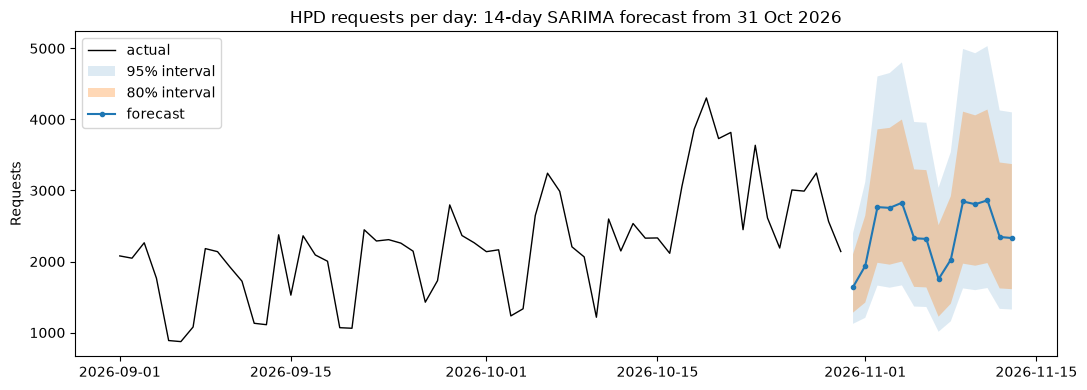

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
recent = y["2026-09-01":]
ax.plot(recent.index, recent, color="black", linewidth=1, label="actual")
ax.fill_between(forecast.index, forecast["lower_95"], forecast["upper_95"], alpha=0.15, label="95% interval")
ax.fill_between(forecast.index, forecast["lower"], forecast["upper"], alpha=0.3, label="80% interval")
ax.plot(forecast.index, forecast["forecast"], marker="o", markersize=3, label="forecast")
ax.set_title("HPD requests per day: 14-day SARIMA forecast from 31 Oct 2026")
ax.set_ylabel("Requests")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES + "forecast_14_days.png", dpi=150)
plt.show()

In [7]:
forecast.to_csv("../data/forecast_daily.csv", index_label="date")

Weekdays come out at about 2,300 to 2,900 requests and weekends at about 1,600 to 2,000. That's below the last two weeks of October, especially on weekends. The model has a weekly pattern but no yearly one, so its weekday levels are mostly built from the summer and it's slow to pick up the start of the heating season. The backtest showed the same thing as undershooting at the start of winter, so the real numbers for November will probably land in the upper half of the intervals.